In [40]:
import pandas as pd
from surprise import Reader, Dataset, SVD
from surprise.model_selection import train_test_split
from surprise import accuracy
from collections import defaultdict

In [41]:
user_item_ratings_subratings = pd.read_csv('../data/filtered/hotelrec_filtered_00001.csv')
ratings_df = user_item_ratings_subratings[['user_id', 'item_id', 'rating']]
ratings_df = ratings_df.sample(n=1_000_000, random_state=42)

In [42]:
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(ratings_df, reader)
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)

In [43]:
# Use the SVD algorithm
algo = SVD(n_factors=50, n_epochs=50, random_state=42)

print("Training the SVD model...")
algo.fit(trainset)
print("Training complete.")

print("\nMaking predictions on the test set...")
predictions = algo.test(testset)
print("Prediction complete.")

Training the SVD model...
Training complete.

Making predictions on the test set...
Prediction complete.


In [44]:
# --- 3. Calculate Prediction Accuracy Metrics ---

print("\n--- Prediction Accuracy Metrics ---")
# Calculate RMSE
rmse = accuracy.rmse(predictions, verbose=False)
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# Calculate MAE
mae = accuracy.mae(predictions, verbose=False)
print(f"Mean Absolute Error (MAE):      {mae:.4f}")


--- Prediction Accuracy Metrics ---
Root Mean Squared Error (RMSE): 0.9898
Mean Absolute Error (MAE):      0.7649


In [45]:
# --- 4. Calculate Ranking Metrics (Precision@k, Recall@k, F1-Score@k) ---

def calculate_ranking_metrics(predictions, k=10, threshold=3.5):
    """
    Calculates Precision@k, Recall@k, and F1-Score@k.
    
    Args:
        predictions (list of Surprise Prediction objects): The output from algo.test().
        k (int): The number of recommendations to consider.
        threshold (float): The rating threshold to consider an item as relevant.
    """
    # First, map the predictions to each user.
    user_est_true = defaultdict(list)
    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions = dict()
    recalls = dict()
    
    # For each user
    for uid, user_ratings in user_est_true.items():
        # Sort user ratings by estimated value (in descending order)
        user_ratings.sort(key=lambda x: x[0], reverse=True)
        
        # Number of relevant items in the top k recommendations
        n_relevant = sum((true_r >= threshold) for (_, true_r) in user_ratings[:k])
        
        # Number of recommended items in top k
        n_rec_k = k
        
        # Number of all relevant items for the user in the test set
        n_total_relevant = sum((true_r >= threshold) for (_, true_r) in user_ratings)
        
        # Precision@k
        precisions[uid] = n_relevant / n_rec_k if n_rec_k != 0 else 0
        
        # Recall@k
        recalls[uid] = n_relevant / n_total_relevant if n_total_relevant != 0 else 0

    # Average precision and recall over all users
    avg_precision = sum(p for p in precisions.values()) / len(precisions)
    avg_recall = sum(r for r in recalls.values()) / len(recalls)
    
    # Calculate F1-Score
    if avg_precision + avg_recall == 0:
        avg_f1 = 0
    else:
        avg_f1 = 2 * (avg_precision * avg_recall) / (avg_precision + avg_recall)
        
    return avg_precision, avg_recall, avg_f1


print("\n--- Ranking Metrics (k=10, relevance threshold=4.0) ---")
precision_at_10, recall_at_10, f1_at_10 = calculate_ranking_metrics(predictions, k=10, threshold=3.5)
print(f"Precision@10: {precision_at_10:.4f}")
print(f"Recall@10:    {recall_at_10:.4f}")
print(f"F1-Score@10:  {f1_at_10:.4f}")


--- Ranking Metrics (k=10, relevance threshold=4.0) ---
Precision@10: 0.0818
Recall@10:    0.7895
F1-Score@10:  0.1482


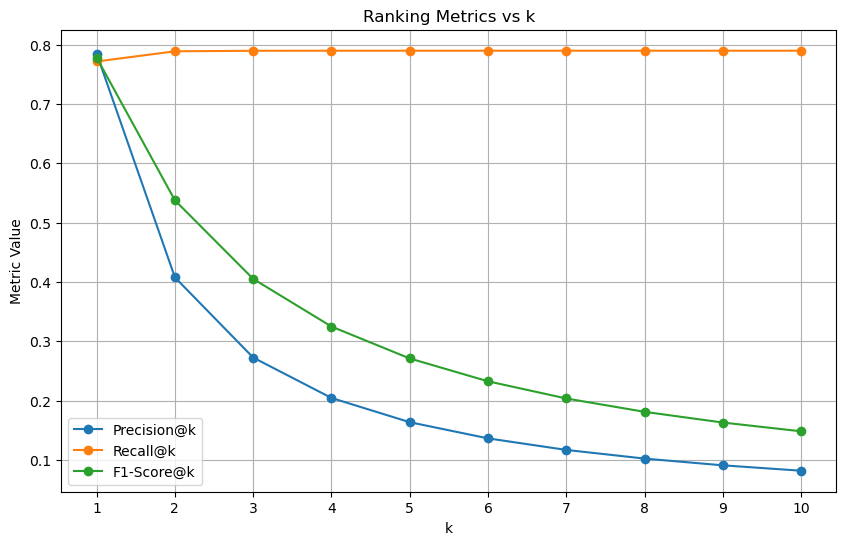

In [46]:
# metric@k plot for k=1 to 10
import matplotlib.pyplot as plt
ks = list(range(1, 11))
precisions = []
recalls = []
f1_scores = []
for k in ks:
    p, r, f1 = calculate_ranking_metrics(predictions, k=k, threshold=3.5)
    precisions.append(p)
    recalls.append(r)
    f1_scores.append(f1)
plt.figure(figsize=(10, 6))
plt.plot(ks, precisions, marker='o', label='Precision@k')
plt.plot(ks, recalls, marker='o', label='Recall@k')
plt.plot(ks, f1_scores, marker='o', label='F1-Score@k')
plt.xlabel('k')
plt.ylabel('Metric Value')
plt.title('Ranking Metrics vs k')
plt.xticks(ks)
plt.legend()
plt.grid()
plt.show()